In [34]:
import numpy as np
import pandas as pd
import matplotlib as plt


data = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-03-churn-prediction/WA_Fn-UseC_-Telco-Customer-Churn.csv'
df = pd.read_csv(data)

df.columns = df.columns.str.lower().str.replace(' ', '_')

categorical_columns = list(df.dtypes[df.dtypes == 'string'].index)

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')

df.totalcharges = pd.to_numeric(df.totalcharges, errors='coerce')
df.totalcharges = df.totalcharges.fillna(0)

df.churn = (df.churn == 'yes').astype(int)

In [35]:
from sklearn.model_selection import train_test_split


df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [36]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction import DictVectorizer

categorical = [
    'gender',
    'seniorcitizen',
    'partner',
    'dependents',
    'phoneservice',
    'multiplelines',
    'internetservice',
    'onlinesecurity',
    'onlinebackup',
    'deviceprotection',
    'techsupport',
    'streamingtv',
    'streamingmovies',
    'contract',
    'paperlessbilling',
    'paymentmethod',
]
numerical = [
    'tenure',
    'monthlycharges',
    'totalcharges'
]

y_train = df_train.churn.values
y_val = df_val.churn.values
y_test = df_test.churn.values




dicts_train = df_train[categorical+numerical].to_dict(orient='records')
dicts_val = df_val[categorical+numerical].to_dict(orient='records')

dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(dicts_train)
X_val = dv.fit_transform(dicts_val)


model = LogisticRegression(solver='lbfgs')
model.fit(X_train,y_train)
y_pred = model.predict_proba(X_val)[:, 1]
churn_decision = (y_pred >= 0.5)
(y_val == churn_decision).mean()

d:\mlZoomcamp\envZoom\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


np.float64(0.8026969481902059)

In [37]:
len(y_val)

1409

In [38]:
(y_val==churn_decision).mean()

np.float64(0.8026969481902059)

In [39]:
from sklearn.metrics import accuracy_score

accuracy_score(y_val,y_pred>=0.5)

0.8026969481902059

0.00 0.274
0.05 0.509
0.10 0.591
0.15 0.666
0.20 0.710
0.25 0.739
0.30 0.760
0.35 0.772
0.40 0.785
0.45 0.793
0.50 0.803
0.55 0.801
0.60 0.795
0.65 0.786
0.70 0.766
0.75 0.744
0.80 0.735
0.85 0.726
0.90 0.726
0.95 0.726
1.00 0.726


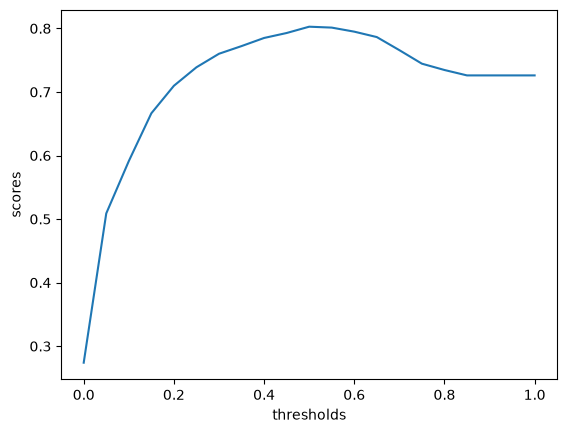

In [40]:
thresholds = np.linspace(0,1,21)
scores = []
for t in thresholds :

    score = accuracy_score(y_val,y_pred>= t)
    print(f'{t:.2f} {score:.3f}')
    scores.append(score)



import matplotlib.pyplot  as plt


plt.plot(thresholds,scores)
plt.xlabel('thresholds')
plt.ylabel('scores')
plt.show()

In [41]:
from collections import Counter

Counter(y_pred>=1.00)

Counter({np.False_: 1409})

In [42]:
1-y_val.mean()

np.float64(0.7260468417317246)

In [43]:
actual_positives = (y_val==1)
actual_negatives = (y_val==0)

t=0.5
predict_positive =(y_pred>=t)
predict_negative =(y_pred<t)

In [44]:
tp = (actual_positives & predict_positive).sum()
print(tp)
tn = (actual_negatives & predict_negative).sum()
print(tn)
fp = (actual_negatives & predict_positive).sum()
print(fp)
fn=  (actual_positives & predict_negative).sum()
print(fn)

210
921
102
176


In [45]:
confusion_matric = np.array(
    [
        [tn,fp],
        [fn,tp]
    ]
)
confusion_matric

array([[921, 102],
       [176, 210]])

In [46]:
(confusion_matric / confusion_matric.sum()).round(2)

array([[0.65, 0.07],
       [0.12, 0.15]])

In [47]:
p = tp / (tp+fp)
p

np.float64(0.6730769230769231)

In [48]:
r= tp / (tp+fn)
r

np.float64(0.5440414507772021)

In [49]:
tpr = tp / (tp+fn)
tpr

np.float64(0.5440414507772021)

In [50]:
fpr = fp /(fp+tn)
fpr

np.float64(0.09970674486803519)

In [51]:
scores = []
thresholds = np.linspace(0,1,101)

for t in thresholds : 

    actual_positives = (y_val==1)
    actual_negatives = (y_val==0)

    predict_positive = (y_pred>= t)
    predict_negative = (y_pred< t)

    tp = (actual_positives & predict_positive).sum()
    fp = (actual_negatives & predict_positive).sum()
    fn=  (actual_positives & predict_negative).sum()
    tn = (actual_negatives & predict_negative).sum()

    scores.append((t,tp,fp,fn,tn))

columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
df_scores = pd.DataFrame(scores,columns=columns)

df_scores['tpr'] = df_scores['tp'] / (df_scores['tp']+df_scores['fn'])
df_scores['fpr'] = df_scores['fp'] / (df_scores['fp']+df_scores['tn'])
    

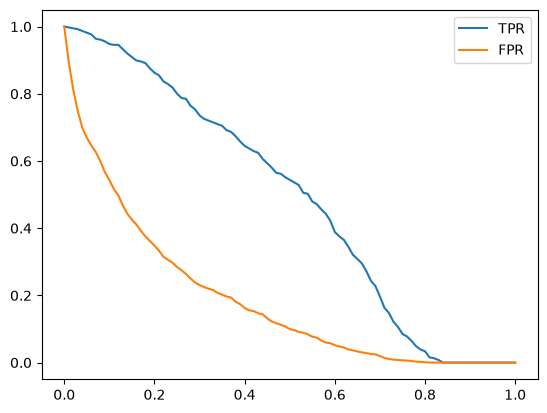

In [52]:
plt.plot(df_scores.threshold,df_scores['tpr'],label='TPR')
plt.plot(df_scores.threshold,df_scores['fpr'],label='FPR')
plt.legend()

In [53]:
numpos = (y_val==1).sum()
numneg= (y_val==0).sum()
y_ideal = np.repeat([0,1], [numneg,numpos])
y_ideal_values = np.linspace(0,1,len(y_val))

accuracy_score(y_ideal,y_ideal>=0.726)

1.0

In [54]:
ideal = []
thresholds = np.linspace(0,1,101)

for t in thresholds : 

    actual_positives = (y_ideal==1)
    actual_negatives = (y_ideal==0)

    predict_positive = (y_ideal_values>= t)
    predict_negative = (y_ideal_values< t)

    tp = (actual_positives & predict_positive).sum()
    fp = (actual_negatives & predict_positive).sum()
    fn=  (actual_positives & predict_negative).sum()
    tn = (actual_negatives & predict_negative).sum()

    ideal.append((t,tp,fp,fn,tn))

columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
df_ideal = pd.DataFrame(ideal,columns=columns)

df_ideal['tpr'] = df_ideal['tp'] / (df_ideal['tp']+df_ideal['fn'])
df_ideal['fpr'] = df_ideal['fp'] / (df_ideal['fp']+df_ideal['tn'])
    

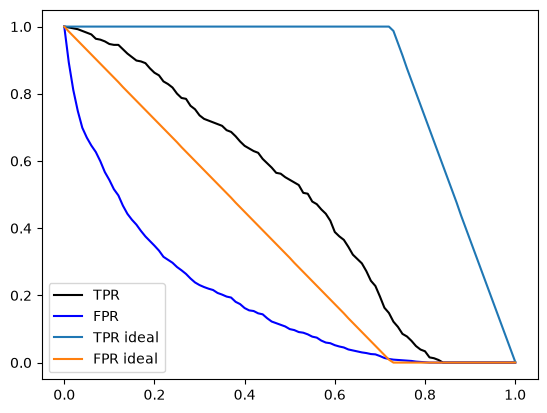

In [55]:
plt.plot(df_scores.threshold, df_scores['tpr'], label='TPR', color='black')
plt.plot(df_scores.threshold, df_scores['fpr'], label='FPR', color='blue')

plt.plot(df_ideal.threshold, df_ideal['tpr'], label='TPR ideal')
plt.plot(df_ideal.threshold, df_ideal['fpr'], label='FPR ideal')

plt.legend()

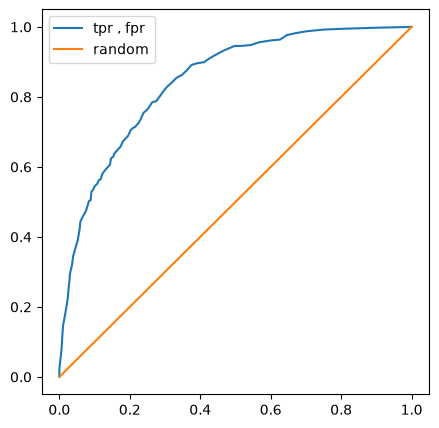

In [56]:
plt.figure(figsize=(5,5))
plt.plot(df_scores.fpr,df_scores.tpr,label='tpr , fpr')
plt.plot([0,1],[0,1],label='random')
plt.legend()

In [57]:
from sklearn.metrics import roc_curve

fpr,tpr,thresholds = roc_curve(y_val,y_pred)

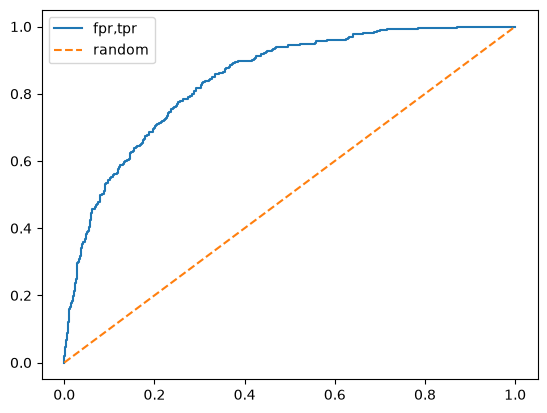

In [58]:
plt.Figure(figsize=(5,5))
plt.plot(fpr,tpr,label='fpr,tpr')
plt.plot([0,1],[0,1],label='random',linestyle='--')
plt.legend()

In [59]:
from sklearn.metrics import auc , roc_auc_score

auc(fpr,tpr)
roc_auc_score(y_val,y_pred)

0.8438555705812935

In [60]:
neg = (y_pred[y_val==0])
pos = (y_pred[y_val==1])

In [61]:
import random
n=10000
success = 0

for i in range(n) :

    pos_ind = random.randint(0 , len(pos)-1)
    neg_idx = random.randint(0, len(neg)-1)


    if pos[pos_ind] > neg[neg_idx] :
        success = success + 1


success/n

0.8443

In [62]:
n = 50000

np.random.seed(1)

pos_idx1 = np.random.randint(0 , len(pos) , size = n)
neg_idx1 = np.random.randint(0 , len(neg) , size = n)

(pos[pos_idx1]> neg[neg_idx1]).mean()

np.float64(0.84654)

In [70]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear',C=C, max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model

In [71]:
def predict(df ,dv , model) :
    dicts = df[categorical+numerical].to_dict(orient='records')

    X = dv.transform(dicts)

    y_pred = model.predict_proba(X)[:,1]
    return y_pred

In [72]:
from sklearn.model_selection import KFold

kFold = KFold(n_splits = 5, shuffle=True, random_state = 1)

In [73]:
from tqdm.auto import tqdm

n_splits = 5

for C in tqdm([0.001, 0.01, 0.1, 0.5, 1, 5, 10]) : 

    kfold = KFold(n_splits,shuffle=True,random_state=1)

    scores = []

    for train_idx , val_idx in kfold.split(df_full_train) :
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.churn.values
        y_val = df_val.churn.values

        dv , model = train(df_train,y_train,C)
        y_pred = predict(df_val,dv,model)

        auc = roc_auc_score(y_val,y_pred)

        scores.append(auc)

    print('C=%s %.3f +- %.3f '% (C,np.mean(scores),np.std(scores)))

  0%|          | 0/7 [00:00<?, ?it/s]

C=0.001 0.825 +- 0.013 
C=0.01 0.839 +- 0.009 
C=0.1 0.841 +- 0.008 
C=0.5 0.841 +- 0.007 
C=1 0.841 +- 0.007 
C=5 0.841 +- 0.007 
C=10 0.841 +- 0.007 


In [74]:
scores

[0.8422141281566202,
 0.8452171070056945,
 0.8335059201284366,
 0.8322708160133018,
 0.8522167487684729]

In [75]:
dv , model  = train(df_full_train,df_full_train.churn.values,C=1.0)
y_pred = predict(df_test,dv,model)

auc =roc_auc_score(y_test,y_pred)
auc

0.8579400803839363